# Titanic Survival Prediction Using Logistic Regression

## 1. Problem Statement

The Titanic sank in 1912. Some passengers survived and many did not. In this project we look at the passenger data and try to build a model that predicts whether a passenger survived or not.

## 2. Motivation

We want to see how a machine learning model can find patterns in old data and use them to make predictions. Here we look at things like age, gender, passenger class and fare, and check how they are related to survival.

## 3. Dataset Description

We use the Titanic passenger dataset. Each row is one passenger. The target column is `Survived`: **0** means the passenger did not survive and **1** means the passenger survived.

The CSV file should be named **`titanic.csv`** and kept in the same folder as this notebook, so the code runs on any teammate's computer.

## 4. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


## 5. Load the Dataset

Keep `titanic.csv` in the same folder as this notebook. Do not use a full path like `C:/Users/...`, because it won't work on someone else's computer.

In [2]:
df = pd.read_csv("titanic.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


## 6. Initial Dataset Exploration

First we take a quick look at the data: a few rows, how many rows and columns there are, the data type of each column, and how many values are missing.

In [3]:
# First five records
display(df.head())

# Dataset dimensions (rows, columns)
print("Dataset shape:", df.shape)

# Column names, non-null counts and data types
print("\nDataset information:")
df.info()

# Missing values in each column
print("\nMissing values:")
display(df.isnull().sum().to_frame(name="Missing Values"))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Dataset shape: (891, 12)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing values:


,Missing Values
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


## 7. Exploratory Data Analysis (EDA)

In EDA we use tables and simple charts to understand the data. We check how many passengers survived and how survival changes with gender, class and age. These charts only show patterns. They do not prove that one thing caused another.

### 7.1 Overall Survival Distribution

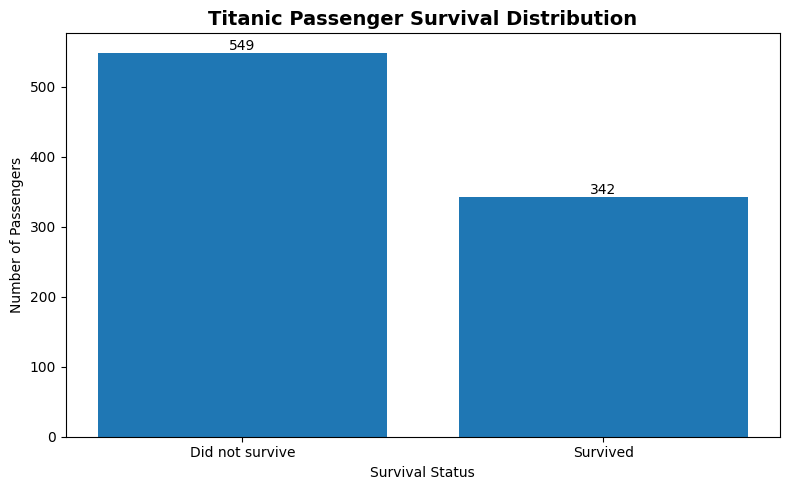

Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival percentages:
Survived
0    61.6
1    38.4
Name: proportion, dtype: float64


In [4]:
counts = df["Survived"].value_counts().reindex([0, 1])
plt.figure(figsize=(8, 5))
bars = plt.bar(["Did not survive", "Survived"], counts.values)
plt.title("Titanic Passenger Survival Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Survival Status")
plt.ylabel("Number of Passengers")
plt.bar_label(bars)
plt.tight_layout()
plt.show()

print("Survival counts:")
print(counts)
print("\nSurvival percentages:")
print((df["Survived"].value_counts(normalize=True).reindex([0, 1]) * 100).round(1))

**Interpretation:** 549 passengers did not survive and 342 survived. So more people died than survived, and the two classes are not equal in size.

### 7.2 Survival Rate by Gender

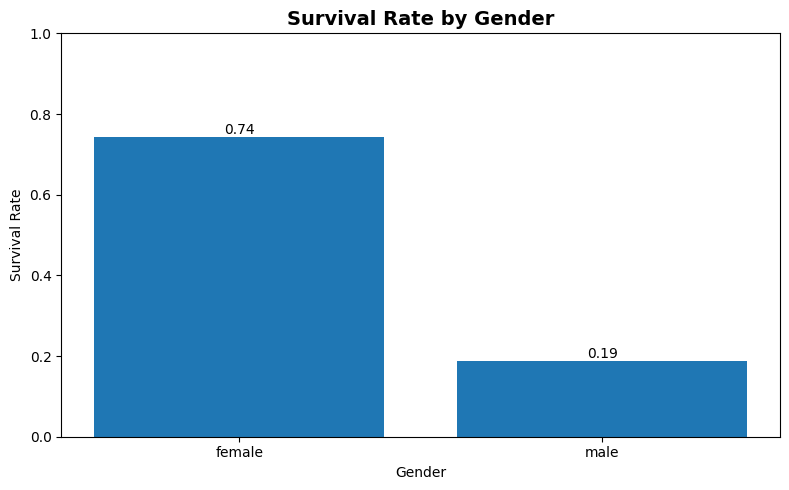

Sex
female    74.2%
male      18.9%
Name: Survived, dtype: object


In [5]:
gender_rates = df.groupby("Sex")["Survived"].mean().reindex(["female", "male"])
plt.figure(figsize=(8, 5))
bars = plt.bar(gender_rates.index, gender_rates.values)
plt.title("Survival Rate by Gender", fontsize=14, fontweight="bold")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.bar_label(bars, fmt="%.2f")
plt.tight_layout()
plt.show()

print((gender_rates * 100).round(1).astype(str) + "%")

**Interpretation:** About 74% of women survived, but only about 19% of men did. This is a big difference, so gender is strongly related to survival.

### 7.3 Survival Rate by Passenger Class

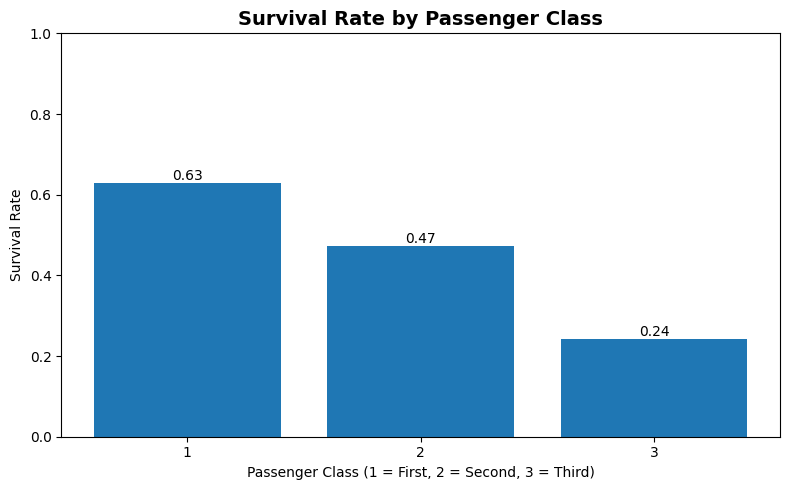

Pclass
1    63.0%
2    47.3%
3    24.2%
Name: Survived, dtype: object


In [6]:
class_rates = df.groupby("Pclass")["Survived"].mean().reindex([1, 2, 3])
plt.figure(figsize=(8, 5))
bars = plt.bar(class_rates.index.astype(str), class_rates.values)
plt.title("Survival Rate by Passenger Class", fontsize=14, fontweight="bold")
plt.xlabel("Passenger Class (1 = First, 2 = Second, 3 = Third)")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.bar_label(bars, fmt="%.2f")
plt.tight_layout()
plt.show()

print((class_rates * 100).round(1).astype(str) + "%")

**Interpretation:** First-class passengers survived the most (about 63%), then second class (about 47%), and third class the least (about 24%). So passenger class is related to survival.

### 7.4 Age Distribution by Survival

/tmp/ipykernel_530/3017959330.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(age_groups, labels=["Did not survive", "Survived"])


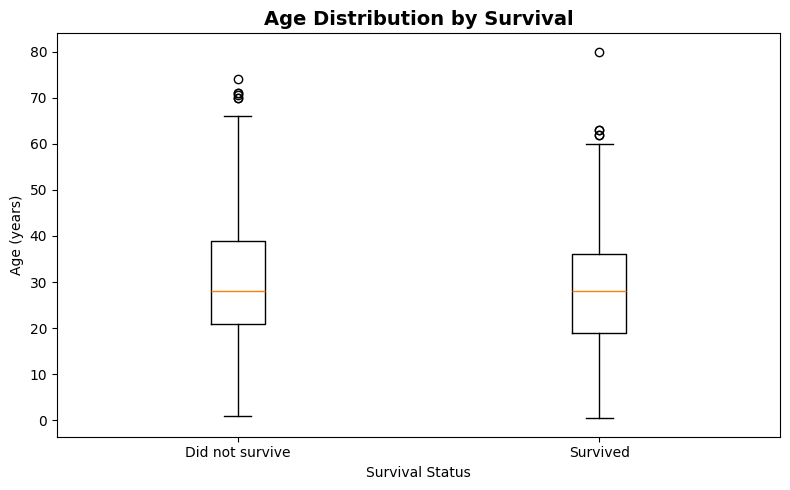

In [7]:
age_groups = [df.loc[df["Survived"] == value, "Age"].dropna() for value in [0, 1]]
plt.figure(figsize=(8, 5))
plt.boxplot(age_groups, labels=["Did not survive", "Survived"])
plt.title("Age Distribution by Survival", fontsize=14, fontweight="bold")
plt.xlabel("Survival Status")
plt.ylabel("Age (years)")
plt.tight_layout()
plt.show()

**Interpretation:** The boxplot compares the ages of passengers who survived and who did not. The two boxes overlap a lot, so age alone does not clearly separate them. Age can still help when we use it together with other features. Passengers with missing age are left out of this plot.

## 8. EDA Conclusion

From the EDA we found:

1. More passengers died than survived.
2. Women had a much higher survival rate than men.
3. First-class passengers survived more than second- and third-class passengers.
4. The ages of survivors and non-survivors overlap, so age is not very useful on its own.

EDA helps us understand the data, spot missing values and decide which features may be useful before training the Logistic Regression model. These are patterns in this dataset only. They do not prove that any one feature caused survival.

## 9. Next Step: Preprocessing

Things to take care of in the next section:

- `Age` has missing values. We can fill them with the median of the training data.
- `Embarked` has only a few missing values. We can fill them with the most common value (mode) of the training data.
- `Cabin` has too many missing values, so we can drop it and mention this in the report.
- `Sex` and `Embarked` are text columns, so we need to convert them to numbers before using Logistic Regression.
- `PassengerId`, `Name` and `Ticket` are just IDs or text, so we can leave them out of the first model.

**Important:** Do the preprocessing steps (like filling missing values) using only the training data, then apply the same steps to the test data. Otherwise information from the test data leaks into training.